<a href="https://colab.research.google.com/github/shubham0109/langgraph-learning/blob/main/AIAgent4_Drafter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install langchain-openai langchain-core langgraph python-dotenv
!pip install langchain-google-genai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 21.2 MB/s  0:00:00
  Attempting uninstall: google-auth
    Found existing installation: google-auth 2.49.0
    Uninstalling google-auth-2.49.0:
      Successfully uninstalled google-auth-2.49.0
  Attempting uninstall: google-genai
    Found existing installation: google-genai 2.12.1
    Uninstalling google-genai-2.12.1:
      Successfully uninstalled google-genai-2.12.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [langchain-google-genai]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


In [2]:
from typing import Annotated, Sequence, TypedDict
from dotenv import load_dotenv
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, ToolMessage, SystemMessage
from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import ToolNode
from langchain_google_genai import ChatGoogleGenerativeAI

In [3]:
document_content = ""

class AgentState(TypedDict):
  messages: Annotated[Sequence[BaseMessage], add_messages]

In [4]:
@tool
def update(content: str) -> str:
  "Updates the document with the provided content."
  global document_content
  document_content = content
  return f"Document has been updated successfully! The current content is:\n{document_content}"


@tool
def save(filename: str) -> str:
  """Save the current document to a text file and finish the process.

    Args:
        filename: Name for the text file.
  """
  global document_content

  if not filename.endswith('.txt'):
    filename = f"{filename}.txt"

  try:
        with open(filename, 'w') as file:
            file.write(document_content)
        print(f"\n💾 Document has been saved to: {filename}")
        return f"Document has been saved successfully to '{filename}'."

  except Exception as e:
        return f"Error saving document: {str(e)}"

tools = [update, save]

In [5]:
import os
from getpass import getpass

# Securely load the Google Gemini API key
gemini_api_key = os.environ.get("GEMINI_API_KEY")

if not gemini_api_key:
    try:
        from google.colab import userdata
        gemini_api_key = userdata.get('GEMINI_API_KEY')
    except Exception:
        gemini_api_key = getpass("Enter your Gemini API Key (from Google AI Studio): ")

os.environ["GEMINI_API_KEY"] = gemini_api_key

# Initialize the free Gemini 2.5 Flash model
model = ChatGoogleGenerativeAI(model="gemini-3.8-flash", google_api_key=gemini_api_key).bind_tools(tools)

Enter your Gemini API Key (from Google AI Studio): ··········


In [8]:
def agent_node(state: AgentState) -> AgentState:
    system_prompt = SystemMessage(content=f"""
    You are Drafter, a helpful writing assistant. You are going to help the user update and modify documents.

    - If the user wants to update or modify content, use the 'update' tool with the complete updated content.
    - If the user wants to save and finish, you need to use the 'save' tool.
    - Make sure to always show the current document state after modifications.

    The current document content is:{document_content}
    """)

    if not state["messages"]:
        user_input = "I'm ready to help you update a document. What would you like to create?"
        user_message = HumanMessage(content=user_input)

    else:
        user_input = input("\nWhat would you like to do with the document? ")
        print(f"\n👤 USER: {user_input}")
        user_message = HumanMessage(content=user_input)

    all_messages = [system_prompt] + list(state["messages"]) + [user_message]

    response = model.invoke(all_messages)

    print(f"\n🤖 AI: {response.content}")
    if hasattr(response, "tool_calls") and response.tool_calls:
        print(f"🔧 USING TOOLS: {[tc['name'] for tc in response.tool_calls]}")

    return {"messages": list(state["messages"]) + [user_message, response]}

In [6]:
def should_continue(state: AgentState) -> str:
    """Determine if we should continue or end the conversation."""

    messages = state["messages"]

    if not messages:
        return "continue"

    # This looks for the most recent tool message....
    for message in reversed(messages):
        # ... and checks if this is a ToolMessage resulting from save
        if (isinstance(message, ToolMessage) and
            "saved" in message.content.lower() and
            "document" in message.content.lower()):
            return "end" # goes to the end edge which leads to the endpoint

    return "continue"

In [14]:
def print_messages(messages):
    """Function I made to print the messages in a more readable format"""
    if not messages:
        return

    for message in messages[-3:]:
        if isinstance(message, ToolMessage):
            print(f"\n🛠️ TOOL RESULT: {message.content}")

In [9]:
graph = StateGraph(AgentState)

graph.add_node("agent_node", agent_node)
graph.add_node("tool_node", ToolNode(tools))

graph.set_entry_point("agent_node")

graph.add_edge("agent_node", "tool_node")


graph.add_conditional_edges(
    "tool_node",
    should_continue,
    {
        "continue": "agent_node",
        "end": END,
    },
)

app = graph.compile()

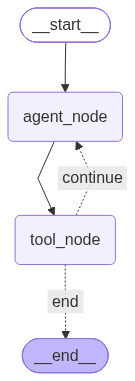

In [11]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [12]:
def run_document_agent():
    print("\n ===== DRAFTER =====")

    state = {"messages": []}

    for step in app.stream(state, stream_mode="values"):
        if "messages" in step:
            print_messages(step["messages"])

    print("\n ===== DRAFTER FINISHED =====")

In [15]:
run_document_agent()


 ===== DRAFTER =====

🤖 AI: [{'type': 'text', 'text': "I'm Drafter, your writing assistant! I'm here to help you draft, edit, and organize your document.\n\nThe document is currently blank. What would you like us to write? Here are a few common ideas if you're deciding:\n\n- **Business / Professional**: Project proposal, business plan, meeting agenda, cover letter, or memo\n- **Technical / Documentation**: README, software requirements, technical guide, or standard operating procedure (SOP)\n- **Creative / Content**: Blog post, newsletter, essay, speech, or short story\n- **Personal / Planning**: Travel itinerary, fitness plan, daily schedule, or goal tracker\n\nTell me what you have in mind (or paste any notes/ideas you already have), and we can get started!", 'extras': {'signature': 'ErwECrkEAWkUfRP9vYK7OXfqgntDR9ogk1IxkIx7cmEbV4Z5WzjxhVWGMOR6Tr+Zi1MWJzNSQi6ozs72tSZE7yA/aJlm7pbbtNogKcO74Obe6Y88pDxj7jA0sKAXTI8ehLZ61EdJclmME+mf7CymOj82LkW5KuFDR3gJ12dcxkWnSyvPmd9J5NLBZVpbmkg66a30gKTWzS